In [33]:
#LOAD THE DATA
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import skew, kurtosis, chi2_contingency


df = pd.read_csv("/Users/annapisarek/Downloads/amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


#  Diving into Amazon UK Product Insights

## Part 1: Analyzing Best-Seller Trends Across Product Categories


### Objective: Understand the relationship between product categories and their best-seller status.

In [9]:
# Create the crosstab
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])

# Display the crosstab
print(crosstab_result)


isBestSeller                    False  True 
category                                    
3D Printers                       247      1
3D Printing & Scanning           4065      2
Abrasive & Finishing Products     245      5
Action Cameras                   1696      1
Adapters                          251      3
...                               ...    ...
Wind Instruments                  243      7
Window Treatments                 234      5
Women                           17559    213
Women's Sports & Outdoor Shoes   1939     20
eBook Readers & Accessories       246      0

[296 rows x 2 columns]


In [17]:


bestseller_count = df['isBestSeller'].sum() 

total_count = df['isBestSeller'].count() 

# Calculate the share of bestsellers
share_of_bestsellers = bestseller_count / total_count

df['share_of_bestsellers'] = share_of_bestsellers




   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...    4.6   

   reviews  price  isBestSeller  boughtInLastMonth        category  \
0    15308  21.99         False                  0  Hi-Fi Speakers   
1    98099  23.99          True                  0  Hi-Fi Speakers   
2    15308  21.99         False                  0  Hi-Fi Speakers   
3     7205  31.99         False                  0  Hi-Fi Speakers   
4     1881  17.99         False                  0  Hi-Fi Speakers   

   share_of_bestsellers  
0              0.003266  
1              0.003266  
2              0.003

In [29]:
# Group by category and calculate the sum of bestsellers and total counts
category_bestseller_counts = df.groupby('category')['isBestSeller'].agg(
    bestseller_count='sum',          # Count of bestsellers (True values)
    total_count='count'             # Total count of products
)

# Calculate the share of bestsellers
category_bestseller_counts['share_of_bestsellers'] = category_bestseller_counts['bestseller_count'] / category_bestseller_counts['total_count']

# Sort by the share of bestsellers in descending order
category_bestseller_counts_sorted = category_bestseller_counts.sort_values(by='share_of_bestsellers', ascending=False)

# Display the results
print(category_bestseller_counts_sorted[['share_of_bestsellers']])


                                  share_of_bestsellers
category                                              
Grocery                                       0.058135
Smart Home Security & Lighting                0.057692
Health & Personal Care                        0.057686
Mobile Phone Accessories                      0.042471
Power & Hand Tools                            0.035339
...                                                ...
CD, Disc & Tape Players                       0.000000
General Music-Making Accessories              0.000000
Snowboard Boots                               0.000000
Boxes & Organisers                            0.000000
eBook Readers & Accessories                   0.000000

[296 rows x 1 columns]


In [38]:


# Perform the Chi-square test
chi2, p_value, dof, expected = chi2_contingency(crosstab_result)

# Display the results
print(f"Chi-square Statistic: {chi2}")
print(f"P-value: {p_value}")


# Interpretation
alpha = 0.05  # significance level
if p_value < alpha:
    print("Reject the null hypothesis: There is a significant association between product category and best-seller status.")
else:
    print("Fail to reject the null hypothesis: There is no significant association between product category and best-seller status.")


Chi-square Statistic: 0.0
P-value: 1.0
Fail to reject the null hypothesis: There is no significant association between product category and best-seller status.


In [52]:

# Create a contingency table
contingency_table = pd.crosstab(df['category'], df['isBestSeller'])

# Check the contingency table for any zero counts
print("Contingency Table:\n", contingency_table)

# Perform the Chi-square test
chi2, p_value, dof, expected = chi2_contingency(contingency_table)


n = contingency_table.sum().sum() 
k = contingency_table.shape[0]     
r = contingency_table.shape[1]      

cramers_v = np.sqrt(chi2 / (n * min(k - 1, r - 1)))
print(f"Cramér's V: {cramers_v}")


Contingency Table:
 isBestSeller                    False  True 
category                                    
3D Printers                       247      1
3D Printing & Scanning           4065      2
Abrasive & Finishing Products     245      5
Action Cameras                   1696      1
Adapters                          251      3
...                               ...    ...
Wind Instruments                  243      7
Window Treatments                 234      5
Women                           17559    213
Women's Sports & Outdoor Shoes   1939     20
eBook Readers & Accessories       246      0

[296 rows x 2 columns]
Cramér's V: 0.1222829439760564


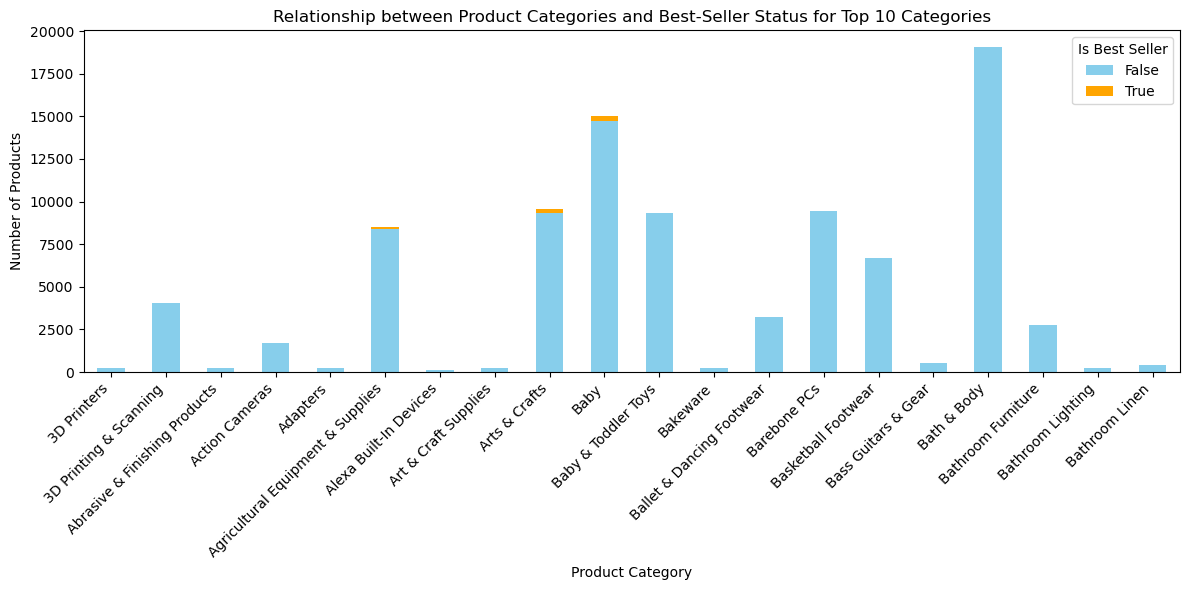

In [63]:
import pandas as pd
import matplotlib.pyplot as plt

# Create a contingency table for product categories and best-seller status
category_bestseller_counts_sorted = pd.crosstab(df['category'], df['isBestSeller']).head(20)

# Plotting
contingency_table.plot(kind='bar', stacked=True, color=['skyblue', 'orange'], figsize=(12, 6))

# Adding labels and title
plt.title('Relationship between Product Categories and Best-Seller Status for Top 10 Categories')
plt.xlabel('Product Category')
plt.ylabel('Number of Products')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Is Best Seller', labels=['False', 'True'])
plt.tight_layout()  # Adjust layout to fit labels

# Show the plot
plt.show()


## Part 2: Exploring Product Prices and Ratings Across Categories and Brands

### Investigate how different product categories influence product prices.

In [74]:
# Calculate Q1 (25th percentile) and Q3 (75th percentile)
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Define lower and upper bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
outliers_iqr = df[
    (df['price'] < lower_bound) |
    (df['price'] > upper_bound)
]

# Remove outliers
filtered_df = df[
    ~df.index.isin(outliers_iqr.index)
]


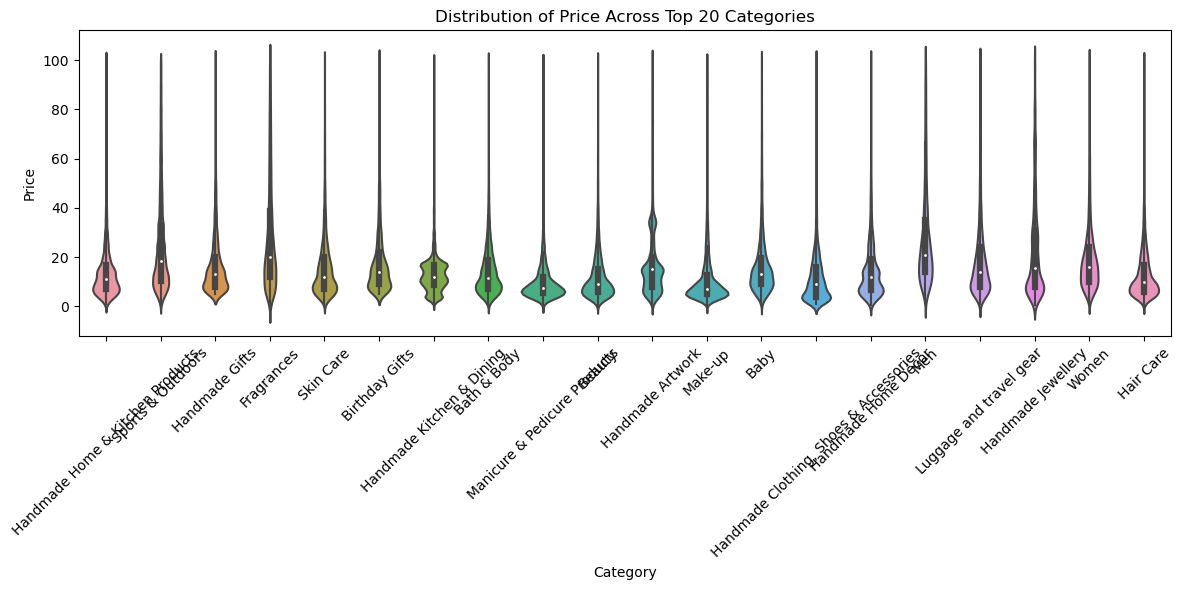

In [78]:
# Count the occurrences of each category and filter the top 20
top_categories = filtered_df['category'].value_counts().nlargest(20).index
filtered_df_2 = filtered_df[filtered_df['category'].isin(top_categories)]

# Create the violin plot
plt.figure(figsize=(12, 6))
sns.violinplot(x='category', y='price', data=filtered_df_2)

# Customize the plot
plt.title('Distribution of Price Across Top 20 Categories')
plt.xlabel('Category')
plt.ylabel('Price')
plt.xticks(rotation=45)  # Rotate category labels for better readability
plt.tight_layout()

# Show the plot
plt.show()

In [80]:

average_price_per_category = filtered_df.groupby('category')['price'].mean()

highest_average_price_category = average_price_per_category.idxmax()
highest_average_price_value = average_price_per_category.max()

# Display the result
print(f"The product category with the highest average price is '{highest_average_price_category}' with an average price of {highest_average_price_value:.2f}.")


The product category with the highest average price is 'Motherboards' with an average price of 68.77.


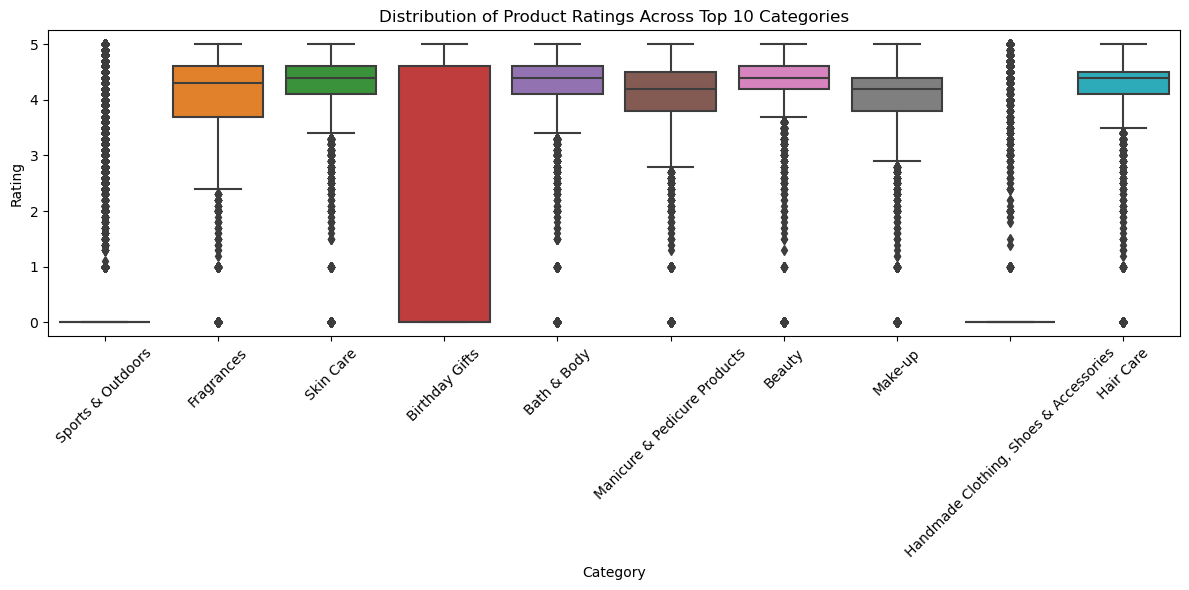

In [116]:
top_categories = filtered_df['category'].value_counts().nlargest(10).index
filtered_df_3 = filtered_df[filtered_df['category'].isin(top_categories)]

# Create the box plot
plt.figure(figsize=(12, 6))
sns.boxplot(x='category', y='stars', data=filtered_df_3)

# Customize the plot
plt.title('Distribution of Product Ratings Across Top 10 Categories')
plt.xlabel('Category')
plt.ylabel('Rating')
plt.xticks(rotation=45)  # Rotate category labels for better readability
plt.tight_layout()

# Show the plot
plt.show()

In [88]:

average_star_per_category = filtered_df.groupby('category')['stars'].mean()

highest_average_star_per_category = average_star_per_category.idxmax()
highest_average_star_value = average_star_per_category.max()


print(f"The product category with the highest average rating is '{highest_average_star_per_category}' with an average rating of {highest_average_star_value:.2f} stars.")


The product category with the highest average rating is 'Luxury Food & Drink' with an average rating of 4.55 stars.


## Part 3: Investigating the Interplay Between Product Prices and Ratings

### Objective: Analyze how product ratings (stars) correlate with product prices.

In [118]:
# Calculate the correlation coefficient between 'price' and 'stars'
correlation_coefficient = filtered_df['price'].corr(filtered_df['stars'])

# Display the result
print(f"The correlation coefficient between price and stars is: {correlation_coefficient:.2f}")
print("which suggests that there is only a slight tendency for the two variables to move in opposite directions. In this case, as the price increases, the stars (ratings) tend to decrease slightly, but the relationship is not strong.")


The correlation coefficient between price and stars is: -0.10
which suggests that there is only a slight tendency for the two variables to move in opposite directions. In this case, as the price increases, the stars (ratings) tend to decrease slightly, but the relationship is not strong.


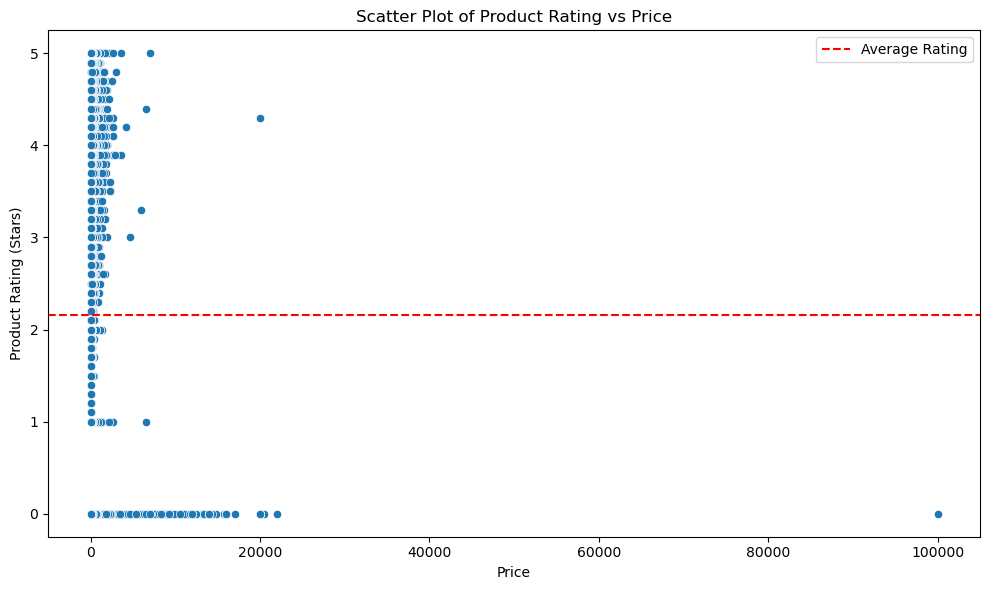

In [120]:

# Create the scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(x='price', y='stars', data=filtered_df)

# Customize the plot
plt.title('Scatter Plot of Product Rating vs Price')
plt.xlabel('Price')
plt.ylabel('Product Rating (Stars)')
plt.axhline(y=df['stars'].mean(), color='r', linestyle='--', label='Average Rating')  # Add average line
plt.legend()
plt.tight_layout()

# Show the plot
plt.show()


##### The most expensive products are not rated often. Cheaper products receive varied rating. Best ratings are with the mid price products.

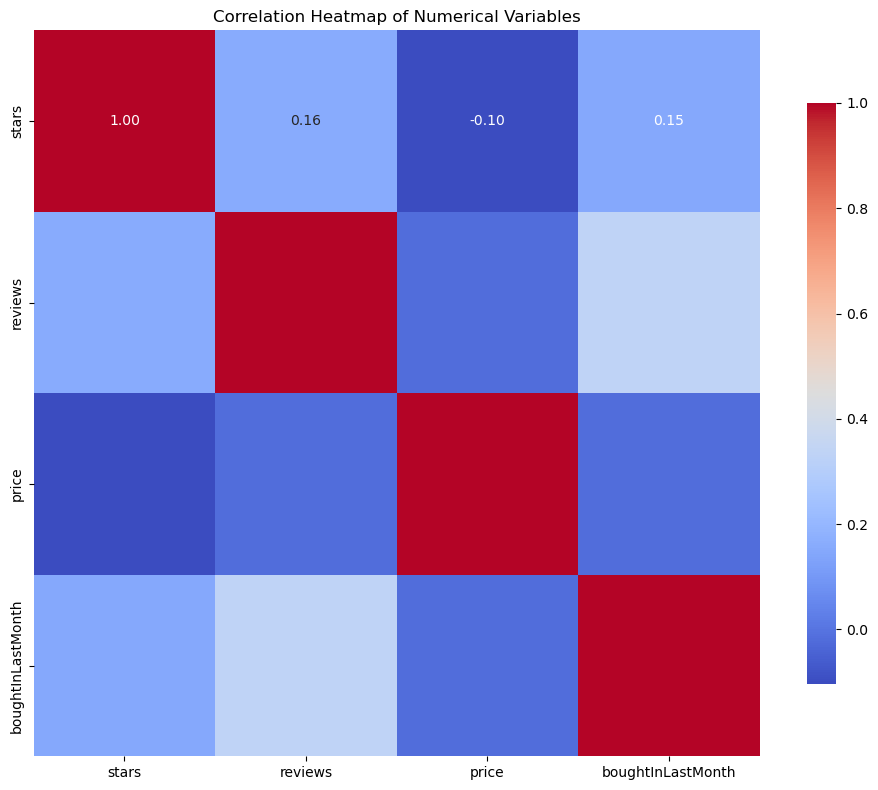

In [122]:

df_num = filtered_df[['stars', 'reviews', 'price', 'boughtInLastMonth']]

# Calculate the correlation matrix
correlation_matrix = df_num.corr()

# Set up the matplotlib figure
plt.figure(figsize=(10, 8))

# Create a heatmap
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True, cbar_kws={"shrink": .8})

# Customize the plot
plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()

# Show the plot
plt.show()


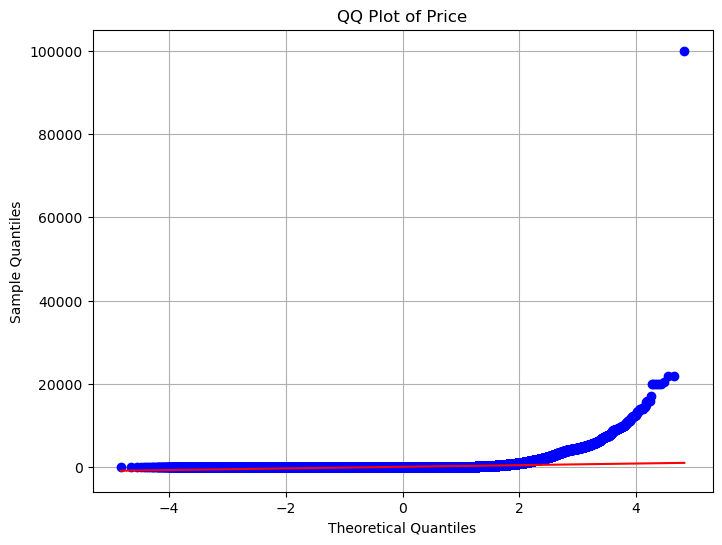

In [124]:

import scipy.stats as stats


plt.figure(figsize=(8, 6))
stats.probplot(filtered_df['price'], dist="norm", plot=plt)

# Customize the plot
plt.title('QQ Plot of Price')
plt.xlabel('Theoretical Quantiles')
plt.ylabel('Sample Quantiles')
plt.grid()

# Show the plot
plt.show()
